In [210]:
# Install the compatible version of protobuf
# !pip install protobuf==3.20.3

In [211]:
import tensorflow as tf
from tensorflow.keras import layers, models, mixed_precision
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import albumentations as A
from tensorflow.keras.optimizers import AdamW

# ENABLE MIXED PRECISION TO SAVE MEMORY
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

# The size of the image file on disk
ORIG_WIDTH = 4096
ORIG_HEIGHT = 256

# The size we will cut out and feed to the model 
PATCH_WIDTH = 256
PATCH_HEIGHT = 256
IMG_SHAPE = (PATCH_HEIGHT, PATCH_WIDTH, 1)
BATCH_SIZE = 8

In [212]:
# Auto-Detect Dataset Path
PROCESSED_BASE_PATH = ""
found = False

for root, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "val" in dirs:
        PROCESSED_BASE_PATH = root
        found = True
        print(f"FOUND DATASET AT: {PROCESSED_BASE_PATH}")
        break

if not found:
    print("Could not find 'train' folder. Defaulting to standard path.")
    PROCESSED_BASE_PATH = "/kaggle/input/aitex-dataset/aitex_dataset_processed"

# Define the paths variables
TRAIN_DIR = os.path.join(PROCESSED_BASE_PATH, "train")
VAL_DIR = os.path.join(PROCESSED_BASE_PATH, "val")

FOUND DATASET AT: /kaggle/input/aitex-dataset/aitex_dataset_processed


In [213]:
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

In [214]:
# ==========================================
# AUGMENTATION
# ==========================================
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    
    # More aggressive brightness/contrast
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    
    # Add elastic deformation (helps with varying defect shapes)
    A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=0.3),
    
    # Grid distortion
    A.GridDistortion(p=0.3),
    
    # Gaussian noise
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    
    # Blur
    A.GaussianBlur(blur_limit=(3, 7), p=0.2),
    
    # CLAHE for contrast enhancement
    A.CLAHE(clip_limit=2.0, p=0.3),
], additional_targets={'mask': 'mask'})

def augment_fn_simple(image, mask):
    # Get numpy arrays
    img_np = image.numpy()
    mask_np = mask.numpy()
    
    # Albumentations expects images in range [0, 255] for uint8
    # Convert normalized float [0,1] to uint8 [0,255]
    img_np = (img_np * 255).astype(np.uint8)
    mask_np = mask_np.astype(np.float32)
    
    # Squeeze to 2D for processing
    img_np = np.squeeze(img_np)  # (256, 256)
    mask_np = np.squeeze(mask_np)  # (256, 256)
    
    # Apply augmentations
    augmented = train_transform(image=img_np, mask=mask_np)
    
    # Get augmented data
    aug_image = augmented['image']
    aug_mask = augmented['mask']
    
    # Convert back to float32 [0, 1] range
    aug_image = aug_image.astype(np.float32) / 255.0
    aug_mask = aug_mask.astype(np.float32)
    
    # Add channel dimension back
    aug_image = np.expand_dims(aug_image, axis=-1)  # (256, 256, 1)
    aug_mask = np.expand_dims(aug_mask, axis=-1)    # (256, 256, 1)
    
    return aug_image, aug_mask

def tf_augment_wrapper_simple(image, mask):
    aug_image, aug_mask = tf.py_function(
        func=augment_fn_simple, 
        inp=[image, mask], 
        Tout=[tf.float32, tf.float32]
    )
    
    # Explicitly set shapes
    aug_image.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
    aug_mask.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
    
    return aug_image, aug_mask

/tmp/ipykernel_47/1527436894.py:12: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=0.3),
/tmp/ipykernel_47/1527436894.py:18: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),


In [215]:
# ==========================================
# DATA LOADING 
# ==========================================
def create_improved_weighted_dataset(data_dir, batch_size):
    """
    More aggressive oversampling strategy:
    - 20x oversampling of defects (instead of 10x)
    - Stratified batching to ensure defects in every batch
    """
    img_folder = os.path.join(data_dir, "images")
    mask_folder = os.path.join(data_dir, "masks")
    
    image_paths = sorted([os.path.join(img_folder, f) for f in os.listdir(img_folder) if f.endswith('.png')])
    
    defect_paths = []
    normal_paths = []
    
    for img_path in image_paths:
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        
        if os.path.exists(mask_path):
            defect_paths.append(img_path)
        else:
            empty_marker = os.path.join(mask_folder, img_filename.replace('.png', '_EMPTY_MASK_PLACEHOLDER.txt'))
            if os.path.exists(empty_marker):
                normal_paths.append(img_path)
    
    print(f"Dataset: {len(defect_paths)} Defects, {len(normal_paths)} Normals.")
    
    # INCREASED oversampling: 20x instead of 10x
    defect_multiplier = 20
    weighted_paths = defect_paths * defect_multiplier + normal_paths
    np.random.shuffle(weighted_paths)
    
    print(f"After weighting: {len(defect_paths) * defect_multiplier} defect samples, {len(normal_paths)} normal samples")
    
    
    def load_and_smart_crop(img_path_tensor):
        img_path = img_path_tensor.numpy().decode('utf-8')
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, 
                                img_filename.replace('.png', '_mask.png'))
        
        # Load full image
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if image is None:
            # Fallback: return zeros if image fails to load
            return (np.zeros((PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=np.float32),
                    np.zeros((PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=np.float32))
        
        h, w = image.shape
        
        # Load or create mask
        if os.path.exists(mask_path):
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask = (mask > 0).astype(np.float32)
        else:
            mask = np.zeros((h, w), dtype=np.float32)
        
        # SMART CROP with guaranteed patch creation
        crop_size = PATCH_WIDTH
        
        # Check if image is wide enough
        if w < crop_size:
            # Pad image if too narrow
            pad_width = crop_size - w
            image = np.pad(image, ((0, 0), (0, pad_width)), mode='reflect')
            mask = np.pad(mask, ((0, 0), (0, pad_width)), mode='constant')
            w = crop_size
        
        # Perform smart crop
        has_defect = os.path.exists(mask_path) and np.sum(mask) > 0
        
        if has_defect:
            y_indices, x_indices = np.where(mask > 0)
            
            # 95% of the time, crop around defect
            if len(x_indices) > 0 and np.random.rand() < 0.95:
                # Pick random defect pixel
                idx = np.random.randint(0, len(x_indices))
                center_x = x_indices[idx]
                
                # Add small jitter
                jitter = np.random.randint(-crop_size//4, crop_size//4)
                center_x = np.clip(center_x + jitter, crop_size//2, w - crop_size//2)
                
                # Calculate crop position
                start_x = max(0, min(center_x - crop_size // 2, w - crop_size))
            else:
                # Random crop as fallback
                start_x = np.random.randint(0, max(1, w - crop_size + 1))
        else:
            # Random crop for normal images
            start_x = np.random.randint(0, max(1, w - crop_size + 1))
        
        # Extract patches - THIS IS NOW GUARANTEED
        img_patch = image[:, start_x:start_x + crop_size]
        mask_patch = mask[:, start_x:start_x + crop_size]
        
        # Ensure correct size
        if img_patch.shape != (PATCH_HEIGHT, crop_size):
            # Fallback: resize if needed
            img_patch = cv2.resize(img_patch, (crop_size, PATCH_HEIGHT))
            mask_patch = cv2.resize(mask_patch, (crop_size, PATCH_HEIGHT))
        
        # Normalize and add channel dimension
        img_patch = np.expand_dims(img_patch, axis=-1).astype(np.float32) / 255.0
        mask_patch = np.expand_dims(mask_patch, axis=-1).astype(np.float32)
        
        return img_patch, mask_patch
    
    # Create dataset
    dataset = tf.data.Dataset.from_tensor_slices(weighted_paths)
    dataset = dataset.map(
        lambda x: tf.py_function(load_and_smart_crop, [x], [tf.float32, tf.float32]),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    
    def set_shapes(image, mask):
        image.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
        mask.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
        return image, mask
    
    dataset = dataset.map(set_shapes)
    dataset = dataset.map(tf_augment_wrapper_simple, 
                         num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    return dataset

def create_tf_datasets_from_processed_files(data_dir, batch_size, is_training=False):
    # Validation Generator
    img_folder = os.path.join(data_dir, "images")
    mask_folder = os.path.join(data_dir, "masks")
    image_paths = sorted([os.path.join(img_folder, f) for f in os.listdir(img_folder) if f.endswith('.png')])
    valid_paths = []
    
    for img_path in image_paths:
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        empty_marker = os.path.join(mask_folder, img_filename.replace('.png', '_EMPTY_MASK_PLACEHOLDER.txt'))
        if os.path.exists(mask_path) or os.path.exists(empty_marker):
            valid_paths.append(img_path)
            
    def patch_generator():
        for img_path in valid_paths:
            img_filename = os.path.basename(img_path)
            mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
            image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if os.path.exists(mask_path):
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                mask = (mask > 0).astype(np.float32)
                mask = np.expand_dims(mask, axis=-1)
            else:
                mask = np.zeros((ORIG_HEIGHT, ORIG_WIDTH, 1), dtype=np.float32)
            
            image = np.expand_dims(image, axis=-1).astype(np.float32) / 255.0
            
            for x in range(0, ORIG_WIDTH, PATCH_WIDTH):
                if x + PATCH_WIDTH > ORIG_WIDTH: break
                img_patch = image[:, x:x+PATCH_WIDTH, :]
                mask_patch = mask[:, x:x+PATCH_WIDTH, :]
                yield img_patch, mask_patch
    
    dataset = tf.data.Dataset.from_generator(
        patch_generator,
        output_signature=(
            tf.TensorSpec(shape=(PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=tf.float32)
        )
    )
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

In [216]:
# Create the datasets
train_dataset = create_weighted_dataset(TRAIN_DIR, BATCH_SIZE)
val_dataset = create_tf_datasets_from_processed_files(VAL_DIR, BATCH_SIZE, is_training=False)

Dataset: 82 Defects, 112 Normals.
After weighting: 820 defect samples, 112 normal samples


In [217]:
# ==========================================
# LOSS FUNCTIONS 
# ==========================================
# 1. CUSTOM METRIC THAT MATCHES YOUR LOSS
def true_dice_metric(y_true, y_pred, smooth=1.0):
    """
    Raw Dice without thresholding - matches what the loss sees
    This is what you should monitor, not the thresholded version
    """
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    dice = (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)
    
    return dice


# 2. EXTREMELY AGGRESSIVE LOSS - PENALIZE BACKGROUND PREDICTIONS
def nuclear_tversky_loss(y_true, y_pred, alpha=0.9, beta=0.1, smooth=1.0):
    """
    Alpha=0.9 means: "I care 9x more about missing defects than false alarms"
    This FORCES the model to predict defects
    """
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    true_pos = tf.reduce_sum(y_true_f * y_pred_f)
    false_neg = tf.reduce_sum(y_true_f * (1 - y_pred_f))  # MISSED DEFECTS - HEAVILY PENALIZED
    false_pos = tf.reduce_sum((1 - y_true_f) * y_pred_f)  # False alarms - lightly penalized
    
    tversky = (true_pos + smooth) / (true_pos + alpha * false_neg + beta * false_pos + smooth)
    
    return 1 - tversky


# 3. ADD WEIGHTED BCE TO FORCE ACTIVATION
def weighted_bce_loss(y_true, y_pred, pos_weight=100.0):
    """
    Defect pixels are worth 100x more than background
    """
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    # Positive class (defects) weighted heavily
    bce = -(pos_weight * y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
    
    return tf.reduce_mean(bce)


# 4. FINAL COMBINED LOSS
def force_learning_loss(y_true, y_pred):
    """
    Combines:
    - 70% Nuclear Tversky (find defects at all costs)
    - 30% Weighted BCE (force high confidence on defects)
    """
    return 0.7 * nuclear_tversky_loss(y_true, y_pred, alpha=0.9, beta=0.1) + \
           0.3 * weighted_bce_loss(y_true, y_pred, pos_weight=100.0)


In [218]:
# ==========================================
# METRICS 
# ==========================================
def dice_coefficient_th(y_true, y_pred, threshold=0.15, smooth=1e-6):  # Lower threshold
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)
    
def recall_metric_th(y_true, y_pred, threshold=0.3):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    actual_positives = tf.reduce_sum(y_true_f)
    
    return true_positives / (actual_positives + 1e-7)

def precision_metric_th(y_true, y_pred, threshold=0.3):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    
    return true_positives / (predicted_positives + 1e-7)

def iou_metric_th(y_true, y_pred, threshold=0.3, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    
    return (intersection + smooth) / (union + smooth)

In [219]:
# ==========================================
# U-NET FOR TINY DEFECTS
# ==========================================
def attention_gate(g, x, filters):
    # Attention mechanism to focus on relevant features
    g1 = layers.Conv2D(filters, 1, padding='same')(g)
    x1 = layers.Conv2D(filters, 1, padding='same')(x)
    psi = layers.Activation('relu')(layers.add([g1, x1]))
    psi = layers.Conv2D(1, 1, padding='same')(psi)
    psi = layers.Activation('sigmoid')(psi)
    return layers.multiply([x, psi])
    
def improved_unet_for_tiny_defects(input_size=IMG_SHAPE):
    inputs = layers.Input(input_size)
    
    # Encoder with residual connections
    # Level 1 - preserve high resolution for tiny defects
    c1 = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(32, 3, activation='relu', padding='same')(c1)
    c1 = layers.BatchNormalization()(c1)
    r1 = layers.Conv2D(32, 1, padding='same')(inputs)  # Residual
    c1 = layers.add([c1, r1])
    p1 = layers.MaxPooling2D(2)(c1)
    p1 = layers.Dropout(0.1)(p1)
    
    # Level 2
    c2 = layers.Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(64, 3, activation='relu', padding='same')(c2)
    c2 = layers.BatchNormalization()(c2)
    r2 = layers.Conv2D(64, 1, padding='same')(p1)
    c2 = layers.add([c2, r2])
    p2 = layers.MaxPooling2D(2)(c2)
    p2 = layers.Dropout(0.1)(p2)
    
    # Level 3
    c3 = layers.Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(128, 3, activation='relu', padding='same')(c3)
    c3 = layers.BatchNormalization()(c3)
    r3 = layers.Conv2D(128, 1, padding='same')(p2)
    c3 = layers.add([c3, r3])
    p3 = layers.MaxPooling2D(2)(c3)
    p3 = layers.Dropout(0.2)(p3)
    
    # Level 4
    c4 = layers.Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(256, 3, activation='relu', padding='same')(c4)
    c4 = layers.BatchNormalization()(c4)
    r4 = layers.Conv2D(256, 1, padding='same')(p3)
    c4 = layers.add([c4, r4])
    p4 = layers.MaxPooling2D(2)(c4)
    p4 = layers.Dropout(0.2)(p4)
    
    # Bottleneck with ASPP (Atrous Spatial Pyramid Pooling)
    b1 = layers.Conv2D(512, 3, activation='relu', padding='same', dilation_rate=1)(p4)
    b2 = layers.Conv2D(512, 3, activation='relu', padding='same', dilation_rate=2)(p4)
    b3 = layers.Conv2D(512, 3, activation='relu', padding='same', dilation_rate=4)(p4)
    bottleneck = layers.concatenate([b1, b2, b3])
    bottleneck = layers.Conv2D(512, 1, activation='relu', padding='same')(bottleneck)
    bottleneck = layers.BatchNormalization()(bottleneck)
    bottleneck = layers.Dropout(0.3)(bottleneck)
    
    # Decoder with attention gates
    u5 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(bottleneck)
    c4_att = attention_gate(u5, c4, 256)
    u5 = layers.concatenate([u5, c4_att])
    c5 = layers.Conv2D(256, 3, activation='relu', padding='same')(u5)
    c5 = layers.Conv2D(256, 3, activation='relu', padding='same')(c5)
    c5 = layers.BatchNormalization()(c5)
    c5 = layers.Dropout(0.2)(c5)
    
    u6 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c5)
    c3_att = attention_gate(u6, c3, 128)
    u6 = layers.concatenate([u6, c3_att])
    c6 = layers.Conv2D(128, 3, activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(128, 3, activation='relu', padding='same')(c6)
    c6 = layers.BatchNormalization()(c6)
    c6 = layers.Dropout(0.1)(c6)
    
    u7 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c6)
    c2_att = attention_gate(u7, c2, 64)
    u7 = layers.concatenate([u7, c2_att])
    c7 = layers.Conv2D(64, 3, activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(64, 3, activation='relu', padding='same')(c7)
    c7 = layers.BatchNormalization()(c7)
    c7 = layers.Dropout(0.1)(c7)
    
    u8 = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c7)
    c1_att = attention_gate(u8, c1, 32)
    u8 = layers.concatenate([u8, c1_att])
    c8 = layers.Conv2D(32, 3, activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(32, 3, activation='relu', padding='same')(c8)
    c8 = layers.BatchNormalization()(c8)
    
    # Deep supervision
    deep_output = layers.Conv2D(1, 1, dtype='float32', name='deep_supervision')(c7)
    deep_output = layers.Activation('sigmoid')(deep_output)
    deep_output = layers.UpSampling2D(2)(deep_output)
    
    # Main output
    main_output = layers.Conv2D(1, 1, 
                           activation='sigmoid',
                           name='main_output',
                           dtype='float32')(c8)
    
    # Average the outputs 
    outputs = layers.average([main_output, deep_output])
    
    # model = models.Model(inputs=[inputs], outputs=[outputs])
    model = models.Model(inputs=inputs, outputs = main_output)
    return model

In [220]:
# ==========================================
# BUILD MODEL
# ==========================================
import gc
del model
gc.collect()
tf.keras.backend.clear_session()

# Rebuild
model = improved_unet_for_tiny_defects()

initial_lr = 1e-3
optimizer=AdamW(
        learning_rate=initial_lr,
        weight_decay=1e-5,  # L2 regularization
        clipnorm=1.0  # Gradient clipping to prevent exploding gradients
)

model.compile(
    optimizer=optimizer,
    loss=force_learning_loss,
    metrics=[
        true_dice_metric,  # Monitor RAW dice, not thresholded
        tf.keras.metrics.Recall(thresholds=0.3, name='recall_30'),
        tf.keras.metrics.Precision(thresholds=0.3, name='precision_30'),
    ]
)

#print(f"\nModel parameters: {model.count_params():,}")
#model.summary()


=== VERIFYING BATCH COMPOSITION ===
Batch 0: 6/8 patches have defects, Defect pixel ratio: 0.0047
Batch 1: 8/8 patches have defects, Defect pixel ratio: 0.0309
Batch 2: 8/8 patches have defects, Defect pixel ratio: 0.0104
Batch 3: 5/8 patches have defects, Defect pixel ratio: 0.0350
Batch 4: 7/8 patches have defects, Defect pixel ratio: 0.0106
Batch 5: 7/8 patches have defects, Defect pixel ratio: 0.0028
Batch 6: 7/8 patches have defects, Defect pixel ratio: 0.0078
Batch 7: 7/8 patches have defects, Defect pixel ratio: 0.0028
Batch 8: 6/8 patches have defects, Defect pixel ratio: 0.0047
Batch 9: 7/8 patches have defects, Defect pixel ratio: 0.0102


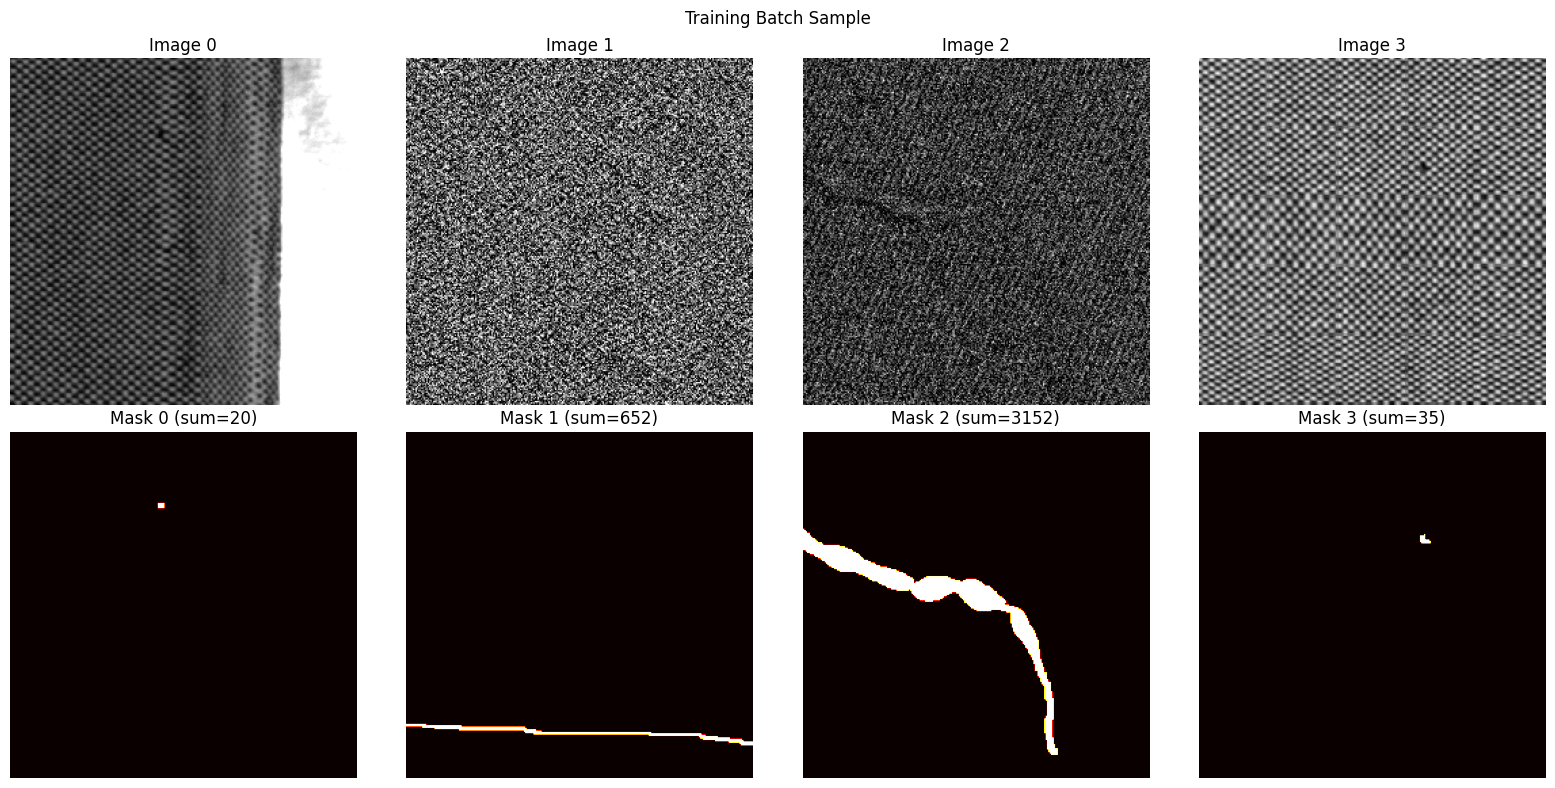

In [221]:
def verify_batch_composition(dataset, num_batches=10):
    print("\n=== VERIFYING BATCH COMPOSITION ===")
    
    for i, (images, masks) in enumerate(dataset.take(num_batches)):
        defect_ratio = tf.reduce_mean(masks).numpy()
        num_defect_patches = tf.reduce_sum(tf.cast(tf.reduce_sum(masks, axis=[1,2,3]) > 0, tf.int32)).numpy()
        
        print(f"Batch {i}: {num_defect_patches}/{len(masks)} patches have defects, "
              f"Defect pixel ratio: {defect_ratio:.4f}")
        
        if defect_ratio < 0.001:
            print(f"Very few defect pixels in this batch")
# Run this before training
verify_batch_composition(train_dataset)
def visualize_training_batch(dataset):
    import matplotlib.pyplot as plt
    
    for images, masks in dataset.take(1):
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        
        for i in range(min(4, len(images))):
            # Show image
            axes[0, i].imshow(images[i].numpy().squeeze(), cmap='gray')
            axes[0, i].set_title(f'Image {i}')
            axes[0, i].axis('off')
            
            # Show mask
            axes[1, i].imshow(masks[i].numpy().squeeze(), cmap='hot')
            axes[1, i].set_title(f'Mask {i} (sum={masks[i].numpy().sum():.0f})')
            axes[1, i].axis('off')
        
        plt.suptitle('Training Batch Sample')
        plt.tight_layout()
        plt.show()
        break

visualize_training_batch(train_dataset)

In [222]:
def diagnose_data_pipeline(dataset, num_batches=5):
    """
    Check if the data pipeline is actually feeding defects
    """
    total_defect_pixels = 0
    total_pixels = 0
    batches_with_defects = 0
    
    for i, (images, masks) in enumerate(dataset.take(num_batches)):
        batch_defect_pixels = tf.reduce_sum(masks).numpy()
        batch_total_pixels = tf.size(masks).numpy()
        batch_has_defects = batch_defect_pixels > 0
        
        total_defect_pixels += batch_defect_pixels
        total_pixels += batch_total_pixels
        
        if batch_has_defects:
            batches_with_defects += 1
        
        print(f"Batch {i}: {int(batch_defect_pixels):,} defect pixels out of {batch_total_pixels:,} "
              f"({batch_defect_pixels/batch_total_pixels*100:.3f}%)")
    
    overall_ratio = total_defect_pixels / total_pixels
    print(f"\nOverall: {batches_with_defects}/{num_batches} batches have defects")
    print(f"Defect pixel ratio: {overall_ratio*100:.4f}%")
    
    if overall_ratio < 0.0001:
        print("\nCRITICAL: Defect ratio is extremely low!")
        print("This explains why the model predicts all zeros.")
        print("Solution: Increase defect oversampling even more.")
    elif batches_with_defects < num_batches * 0.8:
        print("\nWARNING: Not all batches contain defects")
        print("The model sees too many pure-background batches.")
    else:
        print("\nData pipeline looks healthy!")
    


# RUN DIAGNOSIS
print("\nRunning pre-training diagnosis...")
diagnose_data_pipeline(train_dataset, num_batches=20)



Running pre-training diagnosis...
Batch 0: 3,258 defect pixels out of 524,288 (0.621%)
Batch 1: 1,865 defect pixels out of 524,288 (0.356%)
Batch 2: 1,263 defect pixels out of 524,288 (0.241%)
Batch 3: 977 defect pixels out of 524,288 (0.186%)
Batch 4: 1,583 defect pixels out of 524,288 (0.302%)
Batch 5: 3,347 defect pixels out of 524,288 (0.638%)
Batch 6: 2,185 defect pixels out of 524,288 (0.417%)
Batch 7: 15,020 defect pixels out of 524,288 (2.865%)
Batch 8: 2,193 defect pixels out of 524,288 (0.418%)
Batch 9: 1,429 defect pixels out of 524,288 (0.273%)
Batch 10: 812 defect pixels out of 524,288 (0.155%)
Batch 11: 10,719 defect pixels out of 524,288 (2.044%)
Batch 12: 73 defect pixels out of 524,288 (0.014%)
Batch 13: 2,164 defect pixels out of 524,288 (0.413%)
Batch 14: 4,161 defect pixels out of 524,288 (0.794%)
Batch 15: 6,159 defect pixels out of 524,288 (1.175%)
Batch 16: 3,433 defect pixels out of 524,288 (0.655%)
Batch 17: 434 defect pixels out of 524,288 (0.083%)
Batch 18: 

In [223]:
# ==========================================
# CALLBACKS 
# ==========================================
def get_lr_schedule(initial_lr=5e-4, epochs=100):
    def cosine_decay(epoch):
        alpha = epoch / epochs
        return initial_lr * (np.cos(alpha * np.pi) + 1) / 2
    return cosine_decay

lr_schedule = tf.keras.callbacks.LearningRateScheduler(get_lr_schedule())

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_true_dice_metric',
        patience=25,
        mode='max',
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_true_dice_metric',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.LearningRateScheduler(
        lambda epoch: initial_lr * 0.5 * (1 + np.cos(np.pi * epoch / 100))
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'attention_unet_best.keras',
        monitor='val_true_dice_metric',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.LambdaCallback(
        on_epoch_end=lambda epoch, logs: print(
            f"\nTraining Dice: {logs.get('true_dice_metric', 0):.4f} | "
            f"Val Dice: {logs.get('val_true_dice_metric', 0):.4f} | "
            f"Val Recall: {logs.get('val_recall_30', 0):.4f} | "
            f"Val Precision: {logs.get('val_precision_30', 0):.4f}"
        )
    )
]

# ==========================================
# TRAIN
# ==========================================
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    callbacks=callbacks, 
    verbose=1
)w

Epoch 1/100
116/117 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - loss: 1.0561 - precision_30: 0.0094 - recall_30: 0.8844 - true_dice_metric: 0.0189

E0000 00:00:1764252658.074206     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764252658.299813     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - loss: 1.0559 - precision_30: 0.0094 - recall_30: 0.8847 - true_dice_metric: 0.0189
Epoch 1: val_true_dice_metric improved from -inf to 0.00492, saving model to attention_unet_best.keras

Training Dice: 0.0210 | Val Dice: 0.0049 | Val Recall: 0.0528 | Val Precision: 0.0015
117/117 ━━━━━━━━━━━━━━━━━━━━ 140s 628ms/step - loss: 1.0558 - precision_30: 0.0094 - recall_30: 0.8849 - true_dice_metric: 0.0189 - val_loss: 0.9904 - val_precision_30: 0.0015 - val_recall_30: 0.0528 - val_true_dice_metric: 0.0049 - learning_rate: 0.0010
Epoch 2/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - loss: 0.9536 - precision_30: 0.0109 - recall_30: 0.9463 - true_dice_metric: 0.0231
Epoch 2: val_true_dice_metric did not improve from 0.00492

Training Dice: 0.0277 | Val Dice: 0.0018 | Val Recall: 0.0009 | Val Precision: 0.0020
117/117 ━━━━━━━━━━━━━━━━━━━━ 40s 255ms/step - loss: 0.9534 - precision_30: 0.0109 - recall_30: 0.9463 - true_dice_metric: 0.0232 - val_loss: 

In [224]:
# ==========================================
# POST-PROCESSING FUNCTIONS
# ==========================================

def remove_small_objects(binary_mask, min_size=50):
    """
    Remove connected components smaller than min_size pixels
    
    Args:
        binary_mask: Binary prediction mask (0s and 1s)
        min_size: Minimum object size in pixels
    
    Returns:
        Cleaned binary mask
    """
    # Label connected components
    labeled_mask, num_features = label(binary_mask)
    
    # Remove small objects
    cleaned_mask = np.zeros_like(binary_mask)
    for i in range(1, num_features + 1):
        component = (labeled_mask == i)
        if np.sum(component) >= min_size:
            cleaned_mask[component] = 1
    
    return cleaned_mask


def morphological_cleanup(binary_mask, kernel_size=3):
    """
    Apply morphological operations to clean up predictions
    
    Args:
        binary_mask: Binary prediction mask (0s and 1s)
        kernel_size: Size of structuring element
    
    Returns:
        Cleaned binary mask
    """
    # Create structuring element
    struct = generate_binary_structure(2, 1)  # 4-connectivity
    # Or for 8-connectivity:
    # struct = generate_binary_structure(2, 2)
    
    # Opening: removes small noise (erosion followed by dilation)
    opened = binary_opening(binary_mask, structure=struct, iterations=1)
    
    # Closing: fills small holes (dilation followed by erosion)
    closed = binary_closing(opened, structure=struct, iterations=1)
    
    return closed


def advanced_postprocessing(binary_mask, 
                            min_defect_size=15,
                            kernel_size=2,
                            fill_holes=True):
    """
    Complete post-processing pipeline
    
    Args:
        binary_mask: Binary prediction mask (0s and 1s)
        min_defect_size: Minimum size of valid defects in pixels
        kernel_size: Size of morphological kernel
        fill_holes: Whether to fill holes inside defects
    
    Returns:
        Cleaned binary mask
    """
    # Step 1: Morphological cleanup
    cleaned = morphological_cleanup(binary_mask, kernel_size)
    
    # Step 2: Fill holes inside defects 
    if fill_holes:
        cleaned = binary_fill_holes(cleaned).astype(np.uint8)
    
    # Step 3: Remove small objects (false positives)
    cleaned = remove_small_objects(cleaned, min_size=min_defect_size)
    
    return cleaned


def postprocess_with_confidence(predictions, 
                                threshold=0.5,
                                min_confidence=0.6,
                                min_defect_size=30):
    """
    Post-processing with confidence-based filtering
    
    Args:
        predictions: Raw model predictions (probabilities, 0-1)
        threshold: Initial threshold for binarization
        min_confidence: Minimum average confidence for keeping a defect
        min_defect_size: Minimum defect size in pixels
    
    Returns:
        Cleaned binary mask
    """
    # Initial binarization
    binary_mask = (predictions > threshold).astype(np.uint8)
    
    # Label connected components
    labeled_mask, num_features = label(binary_mask)
    
    # Filter by confidence
    cleaned_mask = np.zeros_like(binary_mask)
    for i in range(1, num_features + 1):
        component = (labeled_mask == i)
        component_size = np.sum(component)
        
        # Check size
        if component_size < min_defect_size:
            continue
        
        # Calculate average confidence for this component
        avg_confidence = np.mean(predictions[component])
        
        # Keep if confidence is high enough
        if avg_confidence >= min_confidence:
            cleaned_mask[component] = 1
    
    return cleaned_mask


# ==========================================
# USAGE EXAMPLE
# ==========================================
def apply_postprocessing_to_predictions(predictions, y_val, X_val, 
                                       threshold=0.15,
                                       visualize=True):
    """
    Apply post-processing to model predictions
    
    Args:
        predictions: Raw model predictions (shape: [N, H, W, 1])
        y_val: Ground truth masks
        X_val: Input images
        threshold: Binarization threshold
        visualize: Whether to show comparison plots
    
    Returns:
        predictions_cleaned: Post-processed predictions
    """
    import matplotlib.pyplot as plt
    
    # Initial binarization
    predictions_binary = (predictions > threshold).astype(np.uint8)
    
    # Apply post-processing to each prediction
    predictions_cleaned = np.zeros_like(predictions_binary)
    
    for i in range(len(predictions)):
        # Extract single mask
        mask = predictions_binary[i].squeeze()
        
        # Apply advanced post-processing
        cleaned = advanced_postprocessing(
            mask,
            min_defect_size=30,      # Adjust based on your defect sizes
            kernel_size=3,
            fill_holes=True
        )
        
        predictions_cleaned[i] = cleaned.reshape(predictions_binary[i].shape)
    
    # Calculate metrics before and after
    print("=== BEFORE POST-PROCESSING ===")
    dice_before = calculate_metrics(y_val, predictions_binary)
    
    print("\n=== AFTER POST-PROCESSING ===")
    dice_after = calculate_metrics(y_val, predictions_cleaned)
    
    print(f"\nImprovement: {(dice_after - dice_before)*100:.2f}% Dice gain")
    
    # Visualize if requested
    if visualize and len(X_val) > 0:
        visualize_postprocessing_results(
            X_val, y_val, predictions_binary, predictions_cleaned
        )
    
    return predictions_cleaned


def calculate_metrics(y_true, y_pred):
    """Calculate Dice coefficient"""
    intersection = np.sum(y_true * y_pred)
    dice = (2.0 * intersection) / (np.sum(y_true) + np.sum(y_pred) + 1e-7)
    return dice


def visualize_postprocessing_results(X_val, y_val, predictions_before, 
                                    predictions_after, num_samples=4):
    """
    Visualize the effect of post-processing
    """
    import matplotlib.pyplot as plt
    
    # Find samples with defects
    defect_indices = [i for i in range(len(y_val)) if np.sum(y_val[i]) > 0]
    sample_indices = defect_indices[:num_samples]
    
    fig, axes = plt.subplots(num_samples, 5, figsize=(20, 4*num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, idx in enumerate(sample_indices):
        # Original image
        axes[i, 0].imshow(X_val[idx].squeeze(), cmap='gray')
        axes[i, 0].set_title('Original')
        axes[i, 0].axis('off')
        
        # Ground truth
        axes[i, 1].imshow(y_val[idx].squeeze(), cmap='hot')
        axes[i, 1].set_title(f'Ground Truth\n{np.sum(y_val[idx])} pixels')
        axes[i, 1].axis('off')
        
        # Before post-processing
        before = predictions_before[idx].squeeze()
        axes[i, 2].imshow(before, cmap='hot')
        dice_before = calculate_metrics(
            y_val[idx].flatten(), 
            before.flatten()
        )
        axes[i, 2].set_title(f'Before Cleanup\n{np.sum(before)} pixels\nDice: {dice_before:.3f}')
        axes[i, 2].axis('off')
        
        # After post-processing
        after = predictions_after[idx].squeeze()
        axes[i, 3].imshow(after, cmap='hot')
        dice_after = calculate_metrics(
            y_val[idx].flatten(), 
            after.flatten()
        )
        axes[i, 3].set_title(f'After Cleanup\n{np.sum(after)} pixels\nDice: {dice_after:.3f}')
        axes[i, 3].axis('off')
        
        # Overlay
        axes[i, 4].imshow(X_val[idx].squeeze(), cmap='gray')
        axes[i, 4].imshow(after, cmap='Reds', alpha=0.6)
        axes[i, 4].set_title(f'Overlay\nImprovement: {(dice_after-dice_before)*100:.1f}%')
        axes[i, 4].axis('off')
    
    plt.suptitle('Post-Processing Comparison', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('postprocessing_comparison.png', dpi=300, bbox_inches='tight')
    print("\nSaved: postprocessing_comparison.png")
    plt.show()


In [225]:
# ==========================================
# PARAMETER TUNING HELPER
# ==========================================

def find_best_postprocessing_params(predictions, y_val, X_val):
    """
    Test different post-processing parameters to find the best
    """
    import matplotlib.pyplot as plt
    
    thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]
    min_sizes = [10, 20, 30, 50, 100]
    
    results = []
    
    print("Testing different post-processing parameters...\n")
    
    for threshold in thresholds:
        for min_size in min_sizes:
            # Binarize
            binary = (predictions > threshold).astype(np.uint8)
            
            # Post-process
            cleaned = np.zeros_like(binary)
            for i in range(len(predictions)):
                mask = binary[i].squeeze()
                cleaned[i] = advanced_postprocessing(
                    mask,
                    min_defect_size=min_size,
                    kernel_size=3,
                    fill_holes=True
                ).reshape(binary[i].shape)
            
            # Calculate metrics
            dice = calculate_metrics(y_val, cleaned)
            
            # Calculate precision and recall
            intersection = np.sum(y_val * cleaned)
            recall = intersection / (np.sum(y_val) + 1e-7)
            precision = intersection / (np.sum(cleaned) + 1e-7)
            
            results.append({
                'threshold': threshold,
                'min_size': min_size,
                'dice': dice,
                'recall': recall,
                'precision': precision
            })
            
            print(f"Threshold: {threshold:.1f}, MinSize: {min_size:3d} -> "
                  f"Dice: {dice:.4f}, Recall: {recall:.4f}, Precision: {precision:.4f}")
    
    # Find best parameters
    best = max(results, key=lambda x: x['dice'])
    print(f"BEST PARAMETERS:")
    print(f"  Threshold: {best['threshold']}")
    print(f"  Min Size: {best['min_size']}")
    print(f"  Dice: {best['dice']:.4f}")
    print(f"  Recall: {best['recall']:.4f}")
    print(f"  Precision: {best['precision']:.4f}")
    
    return best

In [226]:
# ==========================================
# LOAD VALIDATION ARRAYS
# ==========================================
def load_validation_arrays(data_dir):
    """
    Loads validation images by slicing them into patches (Tiling).
    Required for visualization.
    """
    img_folder = os.path.join(data_dir, "images")
    mask_folder = os.path.join(data_dir, "masks")
    X_val_list, y_val_list = [], []
    
    # Scan all images
    image_paths = sorted([os.path.join(img_folder, f) for f in os.listdir(img_folder) if f.endswith('.png')])
    
    for img_path in image_paths:
        img_filename = os.path.basename(img_path)
        
        # Check files
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        empty_marker = os.path.join(mask_folder, img_filename.replace('.png', '_EMPTY_MASK_PLACEHOLDER.txt'))
        
        if not (os.path.exists(mask_path) or os.path.exists(empty_marker)):
            continue
            
        # 1. Load ORIGINAL Full Size (4096 x 256)
        image_full = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if os.path.exists(mask_path):
            mask_full = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask_full = (mask_full > 0).astype(np.float32)
        else:
            mask_full = np.zeros((ORIG_HEIGHT, ORIG_WIDTH), dtype=np.float32)
            
        # 2. Tile the image (Cut into 16 patches of 256x256)
        for x in range(0, ORIG_WIDTH, PATCH_WIDTH):
            if x + PATCH_WIDTH > ORIG_WIDTH: break
            
            img_patch = image_full[:, x:x+PATCH_WIDTH]
            mask_patch = mask_full[:, x:x+PATCH_WIDTH]
            
            # Only keep patch if it matches expected size
            if img_patch.shape == (PATCH_HEIGHT, PATCH_WIDTH):
                X_val_list.append(img_patch / 255.0)
                y_val_list.append(mask_patch)

    if len(X_val_list) == 0:
        print("WARNING: No valid validation data found after filtering!")
        return np.array([]), np.array([])

    X_val = np.expand_dims(np.array(X_val_list).astype(np.float32), axis=-1)
    y_val = np.expand_dims(np.array(y_val_list).astype(np.float32), axis=-1)
    return X_val, y_val

98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step

Prediction Stats: Min=0.0000, Max=1.0000, Mean=0.0103
=== BEFORE POST-PROCESSING ===

=== AFTER POST-PROCESSING ===

Improvement: 0.56% Dice gain

Saved: postprocessing_comparison.png


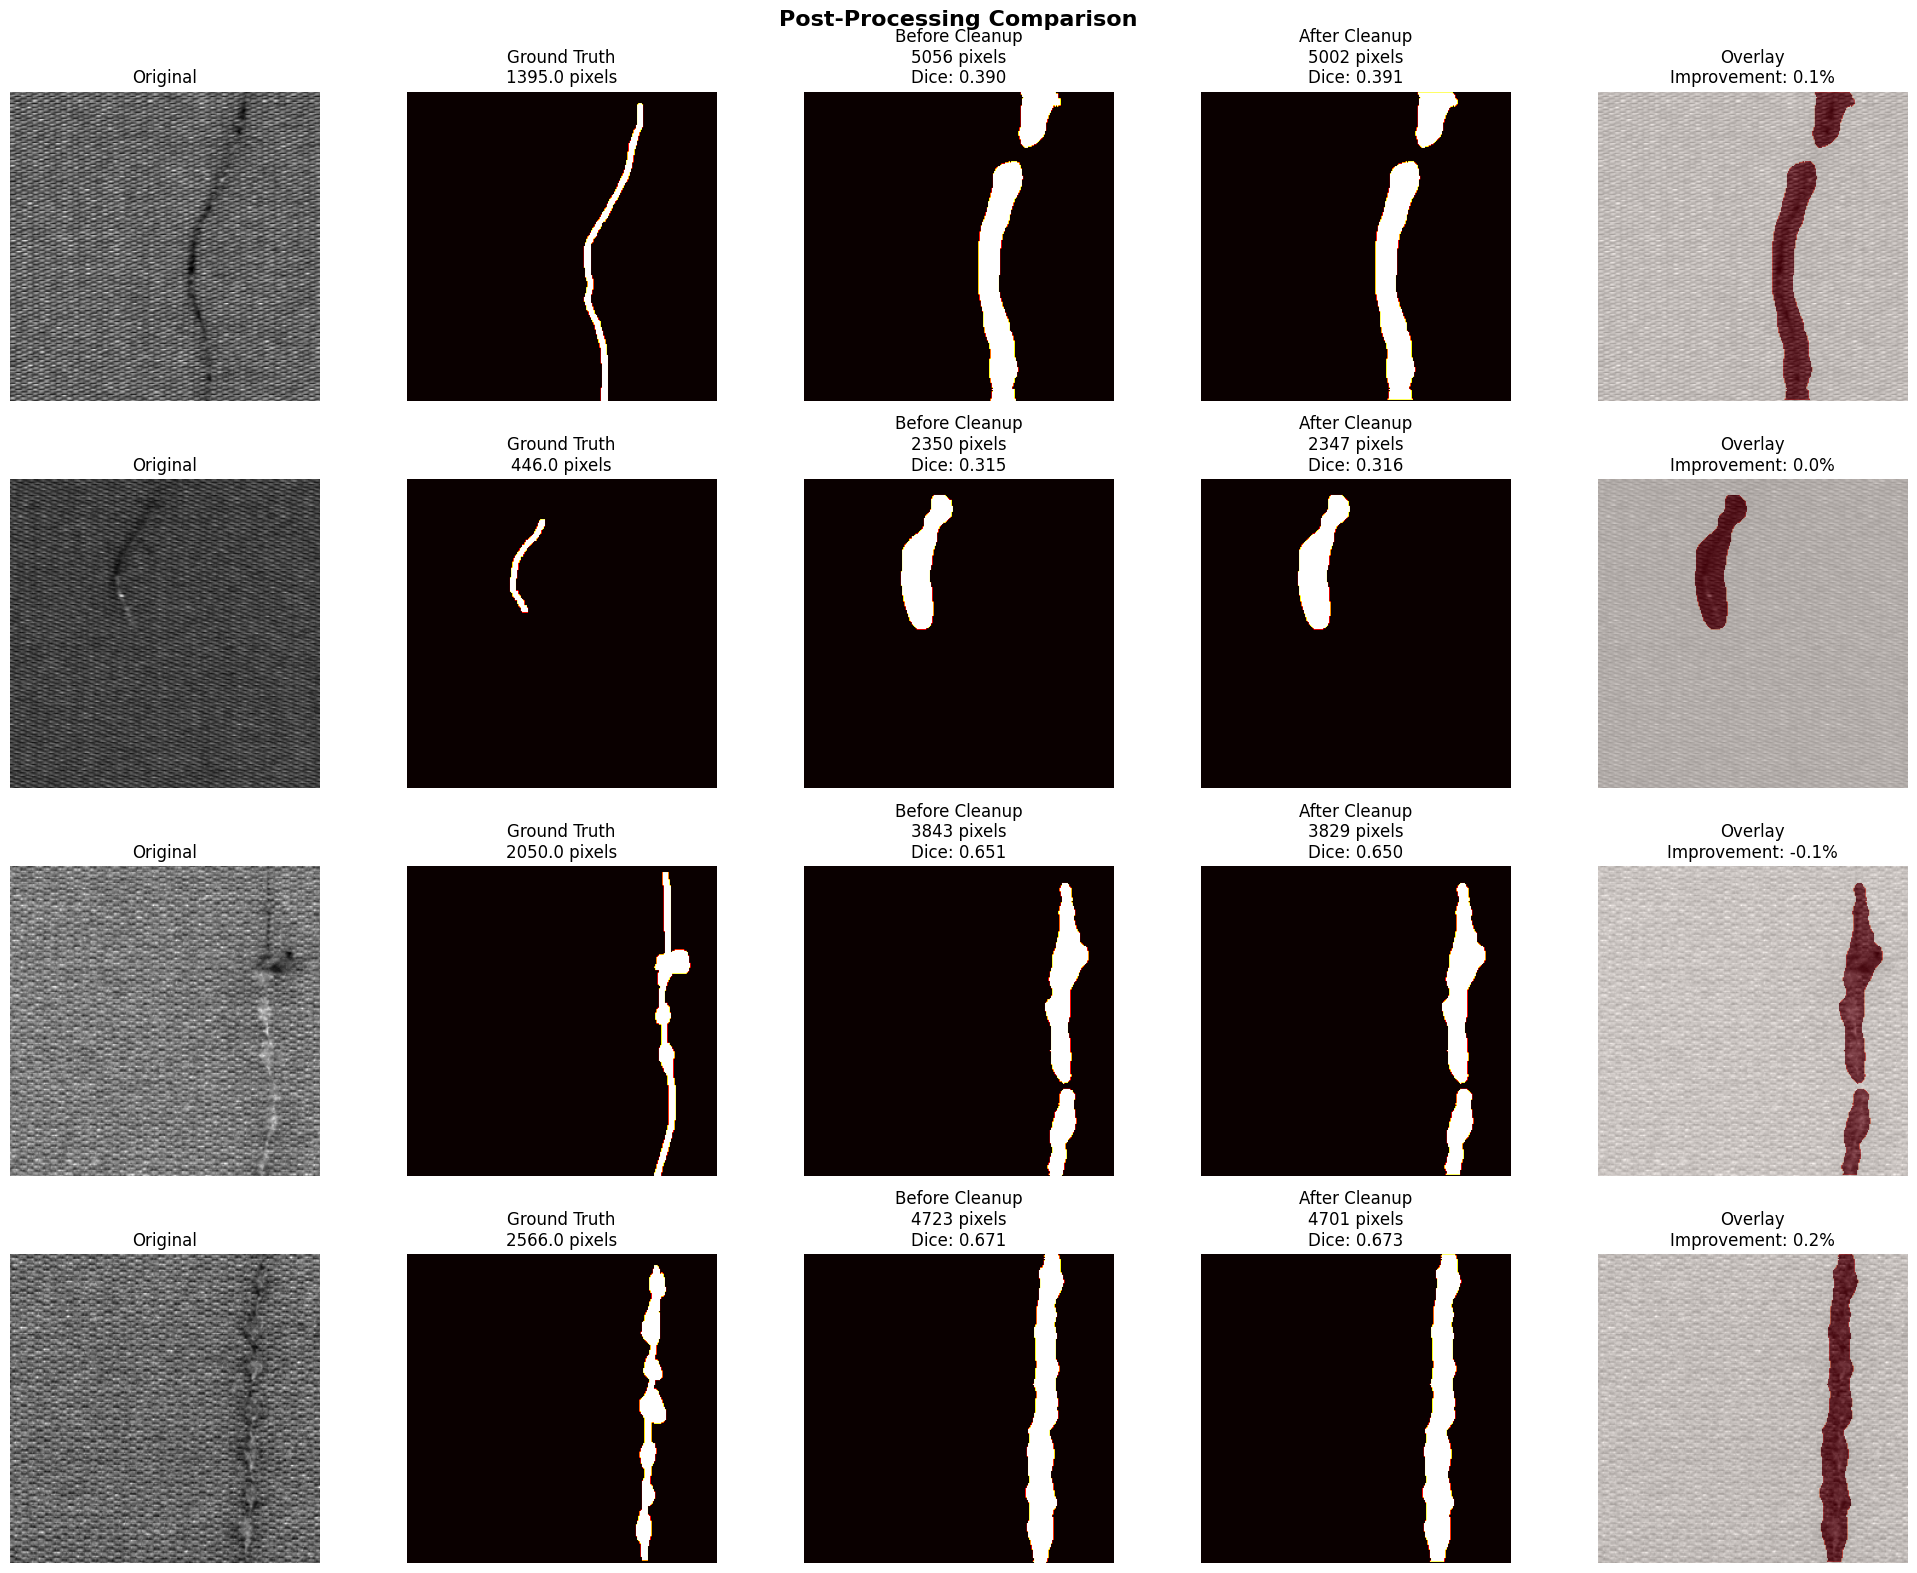

array([[[[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        ...,

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]]],


       [[[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        [[0],
         [0],
         [0],
         ...,
         [0],
         [0],
         [0]],

        ...,

        [[0],
         [0],
         [0],
         ...,
         [0],


In [227]:
from scipy.ndimage import label, generate_binary_structure, binary_opening, binary_closing, binary_fill_holes

# 1. Load the validation images as Arrays (for visualization)
X_val, y_val = load_validation_arrays(VAL_DIR)

# 2. Get predictions from your trained model
# We use the val_dataset to ensure pre-processing matches exactly
predictions = model.predict(val_dataset)

print(f"\nPrediction Stats: Min={predictions.min():.4f}, Max={predictions.max():.4f}, Mean={predictions.mean():.4f}")
"""
max_conf = predictions.max()
print(f"Max Confidence in this batch: {max_conf:.6f}")

# If max confidence is very low, use a tiny threshold
if max_conf < 0.1:
    actual_threshold = max_conf / 2.0  # Use half the max as the cutoff
else:
    actual_threshold = 0.5

print(f"Applying Threshold: {actual_threshold:.6f}")"""
# 3. Visualize the results (Original vs Ground Truth vs Prediction)
apply_postprocessing_to_predictions(
        predictions, 
        y_val, 
        X_val, 
        threshold=0.2, 
        visualize=True)

Max Value in Predictions: 1.0000
Min Value in Predictions: 0.0000
Mean Value: 0.0103


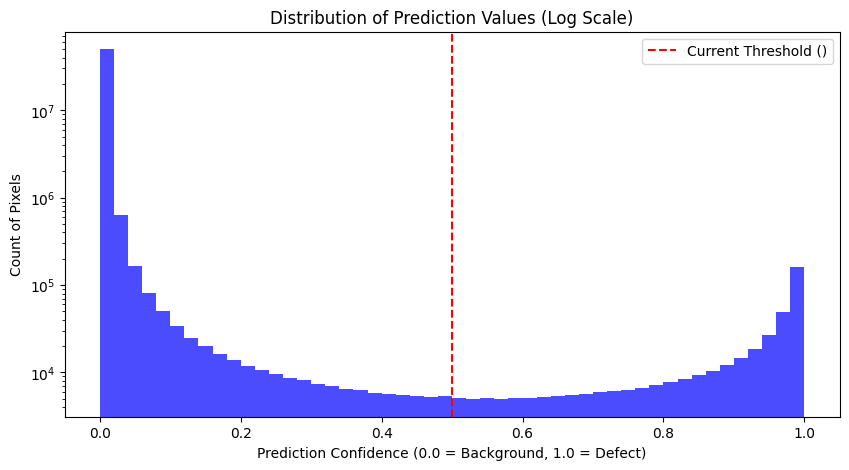


Testing with Lower Threshold: 0.5000

Testing Threshold: 0.1
=== BEFORE POST-PROCESSING ===

=== AFTER POST-PROCESSING ===

Improvement: 0.77% Dice gain

Saved: postprocessing_comparison.png


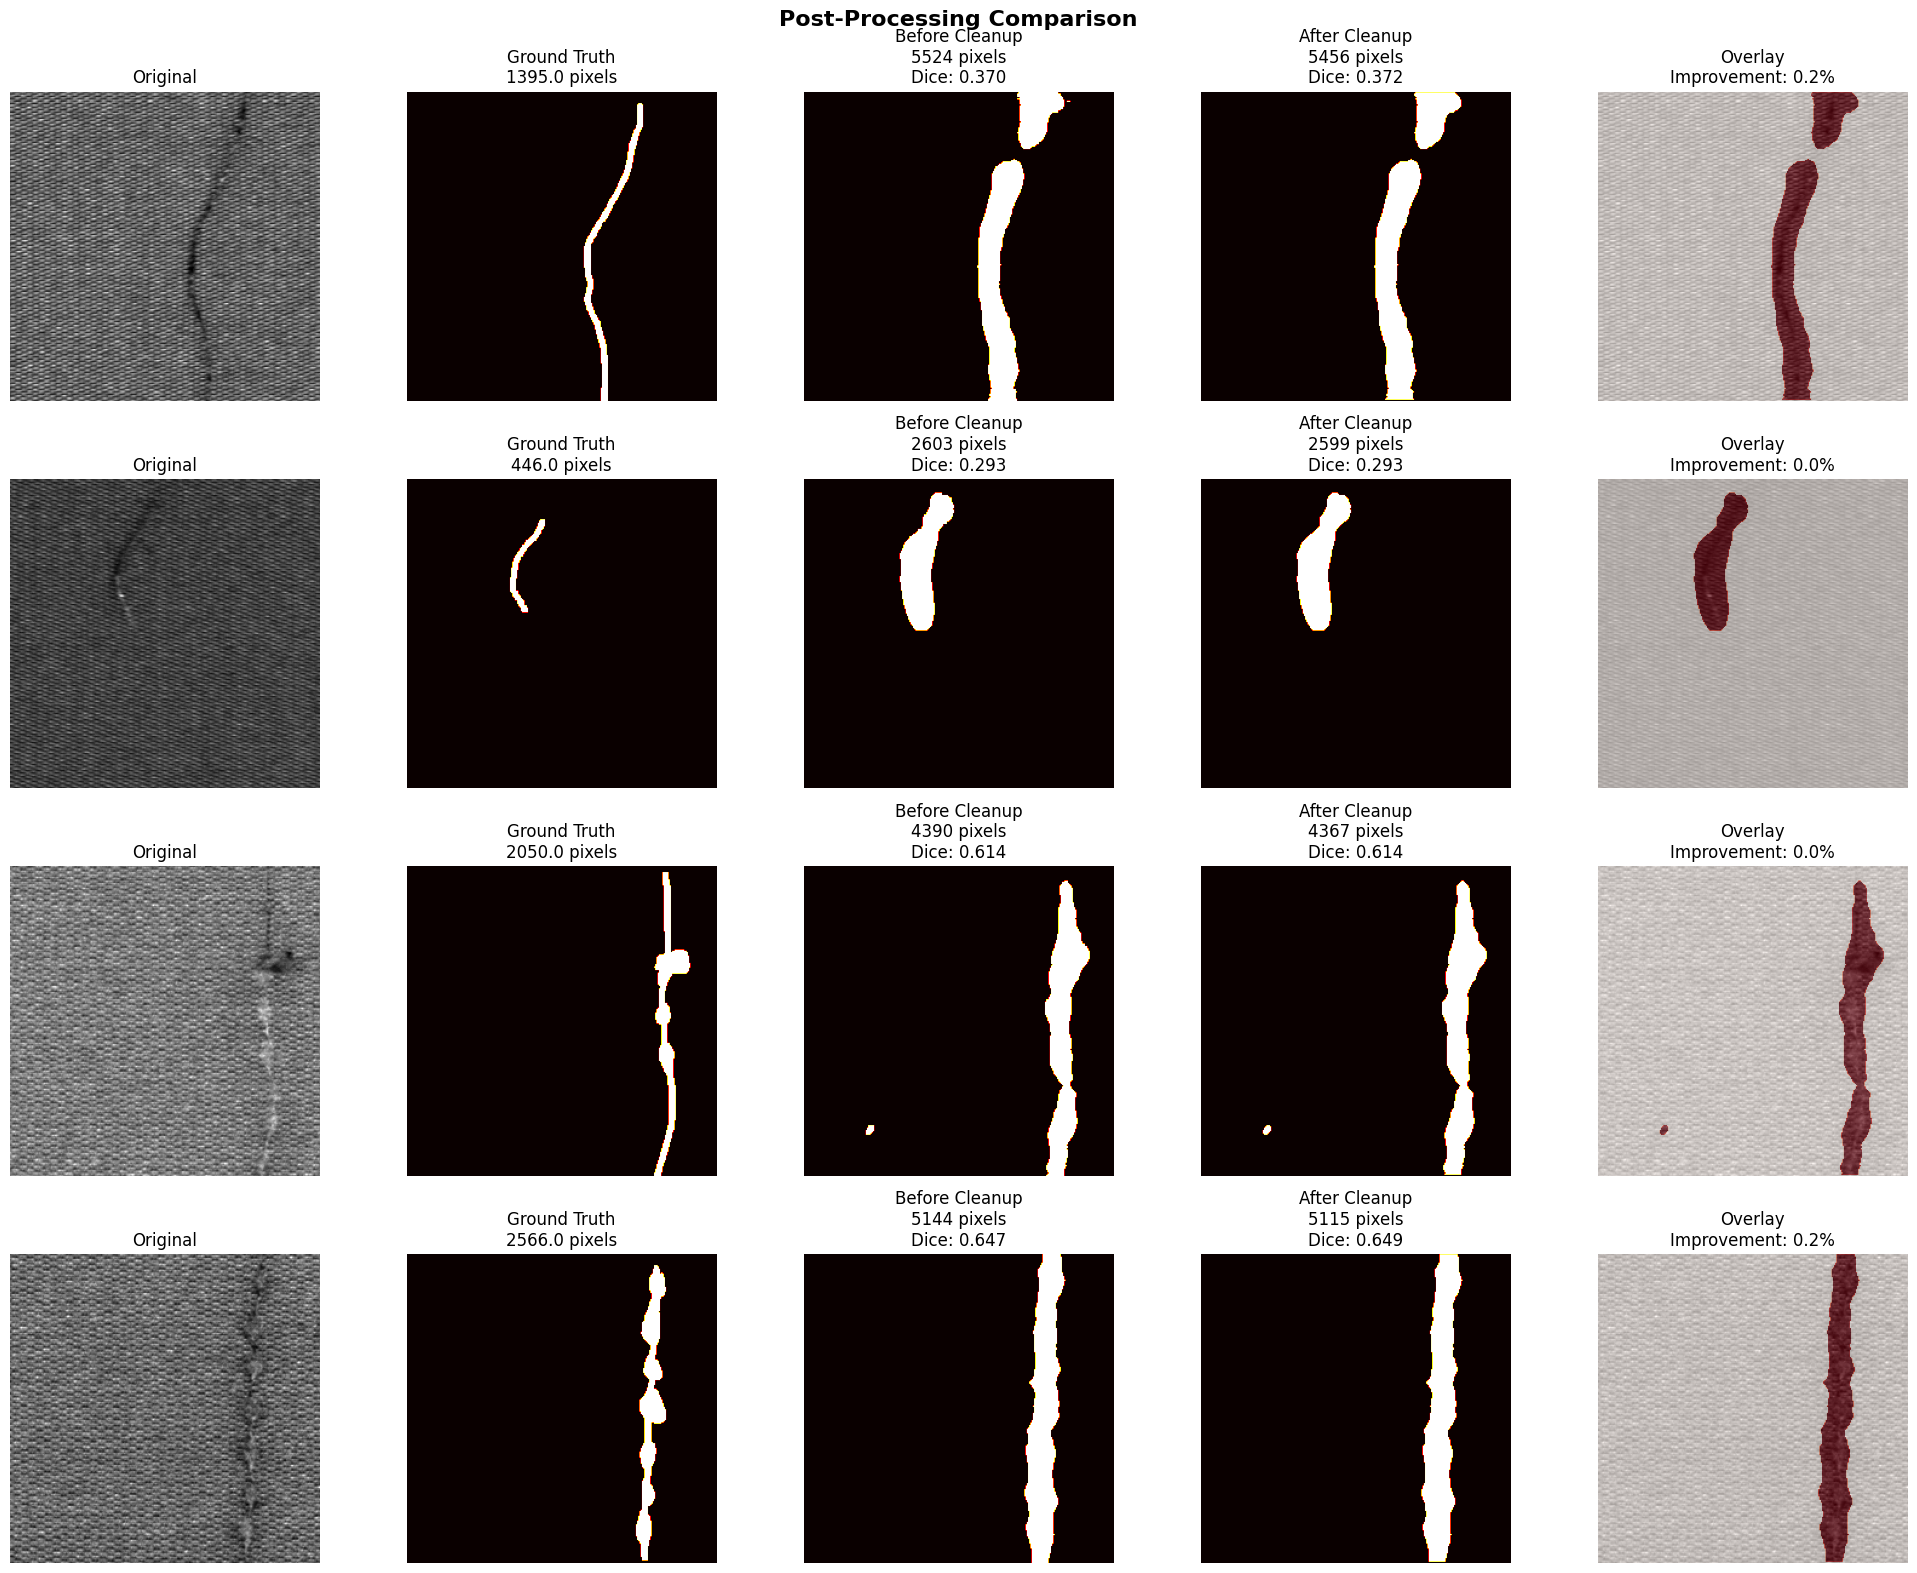


Testing Threshold: 0.2
=== BEFORE POST-PROCESSING ===

=== AFTER POST-PROCESSING ===

Improvement: 0.56% Dice gain

Saved: postprocessing_comparison.png


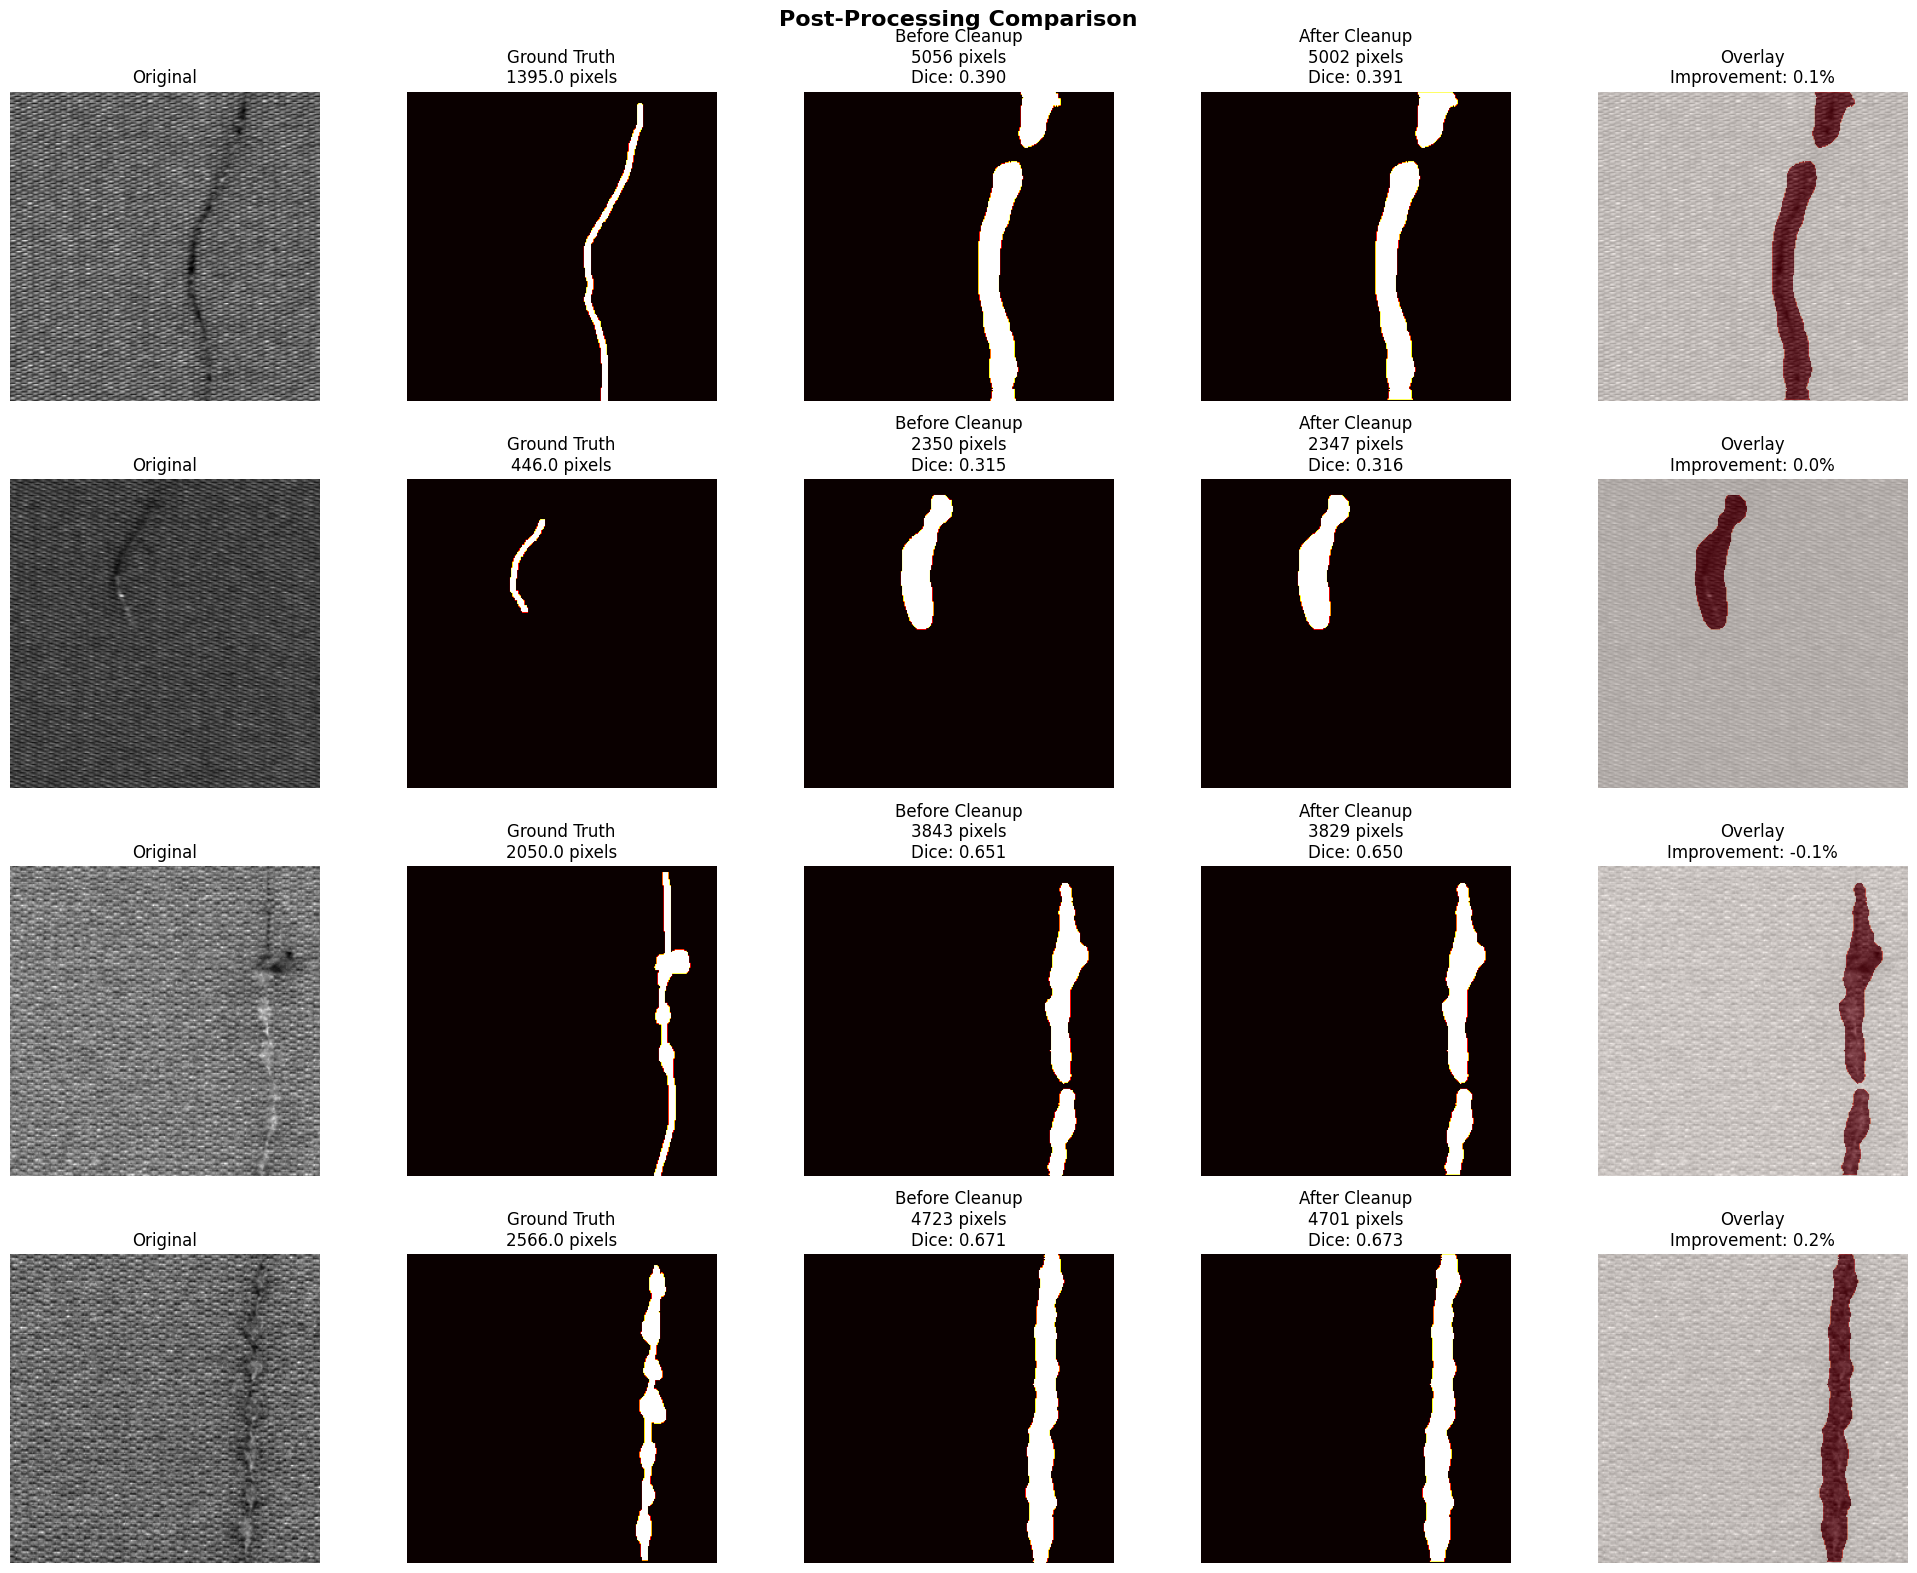


Testing Threshold: 0.3
=== BEFORE POST-PROCESSING ===

=== AFTER POST-PROCESSING ===

Improvement: 0.60% Dice gain

Saved: postprocessing_comparison.png


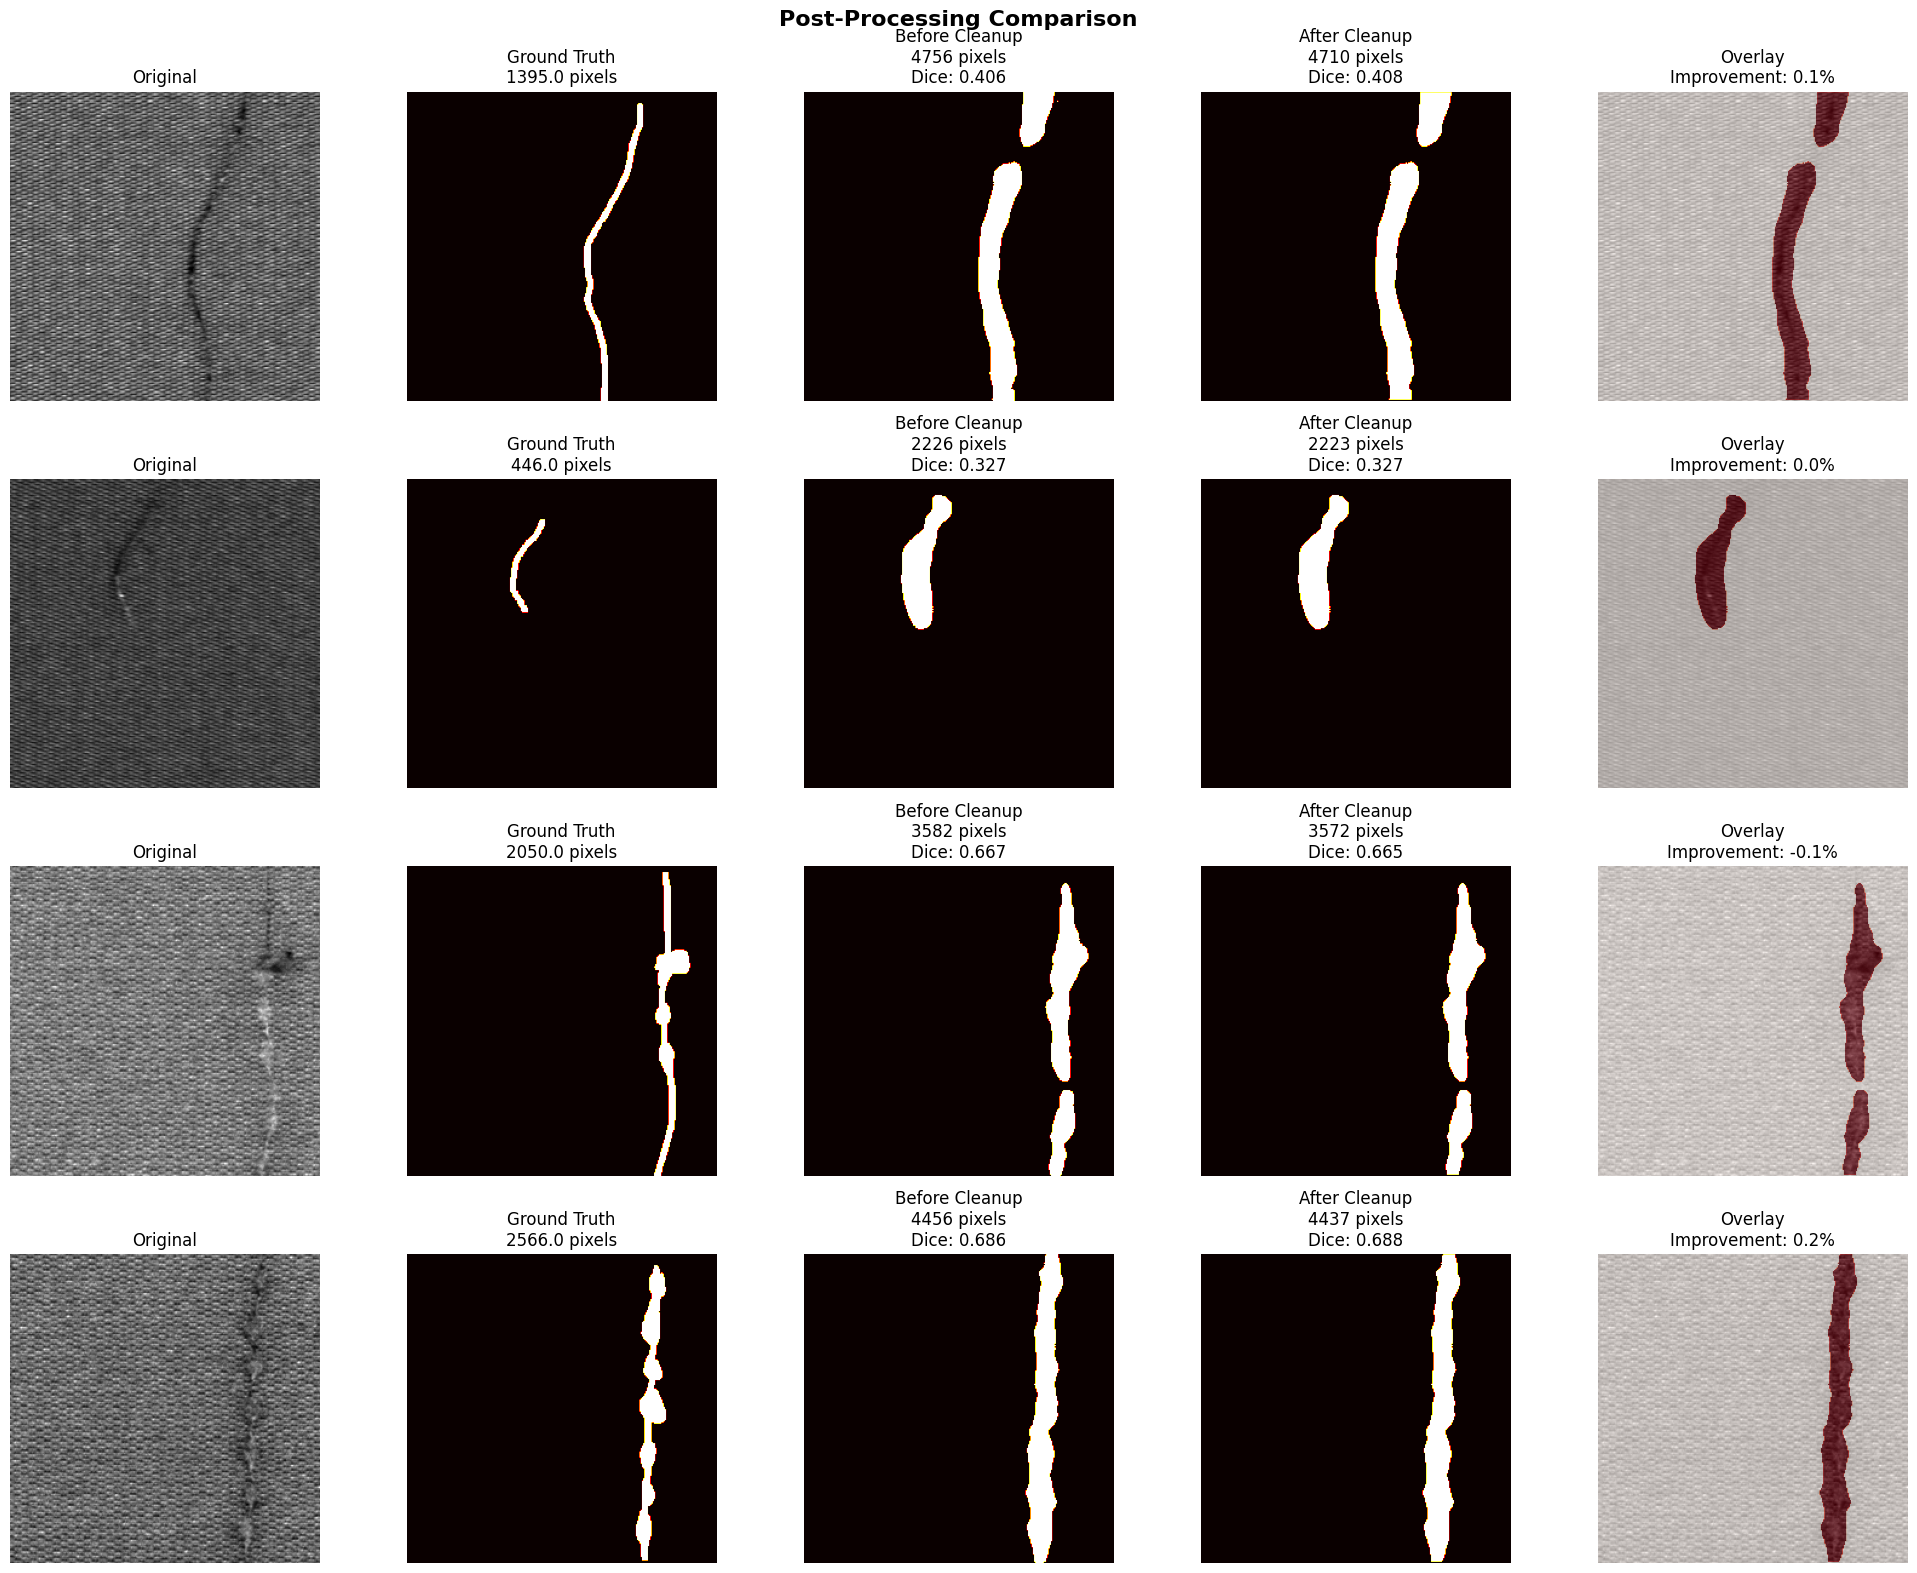

In [228]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import label, generate_binary_structure, binary_opening, binary_closing, binary_fill_holes

# Check the Range of Predictions
print(f"Max Value in Predictions: {predictions.max():.4f}")
print(f"Min Value in Predictions: {predictions.min():.4f}")
print(f"Mean Value: {predictions.mean():.4f}")

# (Probability Density Function) / Histogram
plt.figure(figsize=(10, 5))
plt.hist(predictions.flatten(), bins=50, log=True, color='blue', alpha=0.7)
plt.title("Distribution of Prediction Values (Log Scale)")
plt.xlabel("Prediction Confidence (0.0 = Background, 1.0 = Defect)")
plt.ylabel("Count of Pixels")
plt.axvline(x=0.5, color='r', linestyle='--', label='Current Threshold ()')
plt.legend()
plt.show()

# Post-Processing with a LOWER Threshold
suggested_threshold = max(0.1, predictions.max() / 2) 
print(f"\nTesting with Lower Threshold: {suggested_threshold:.4f}")

test_thresholds = [0.1, 0.2, 0.3]

for th in test_thresholds:
    print(f"\nTesting Threshold: {th}")
    apply_postprocessing_to_predictions(
        predictions, 
        y_val, 
        X_val, 
        threshold=th, 
        visualize=True
    )

--- VISUALIZING RAW PROBABILITY HEATMAPS ---
Red/Yellow = High Probability of Defect
Blue       = Low Probability (Background)

Sample 22: Pred Range [0.0000 - 0.9372]


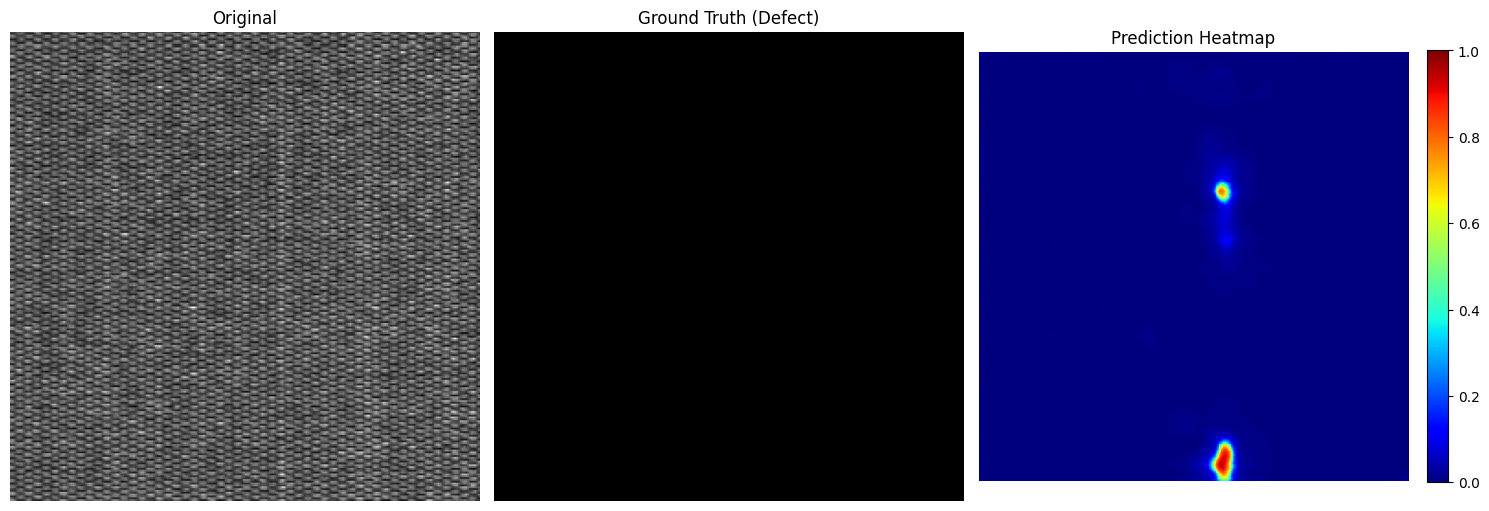

Sample 678: Pred Range [0.0000 - 0.0247]


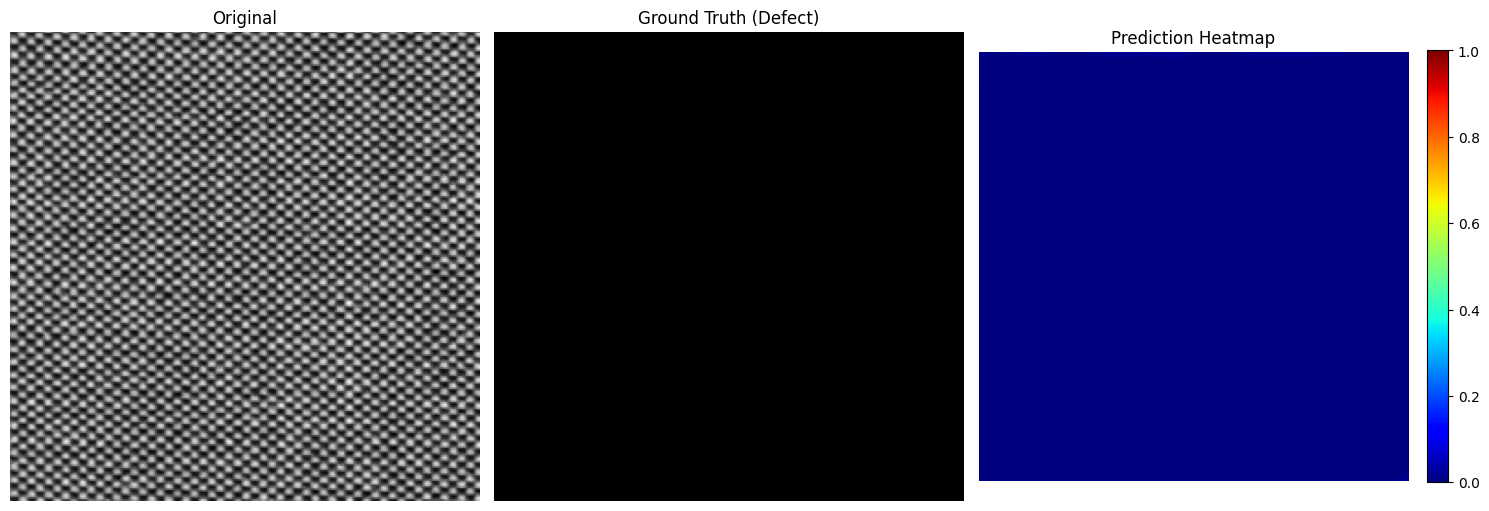

Sample 194: Pred Range [0.0000 - 0.1039]


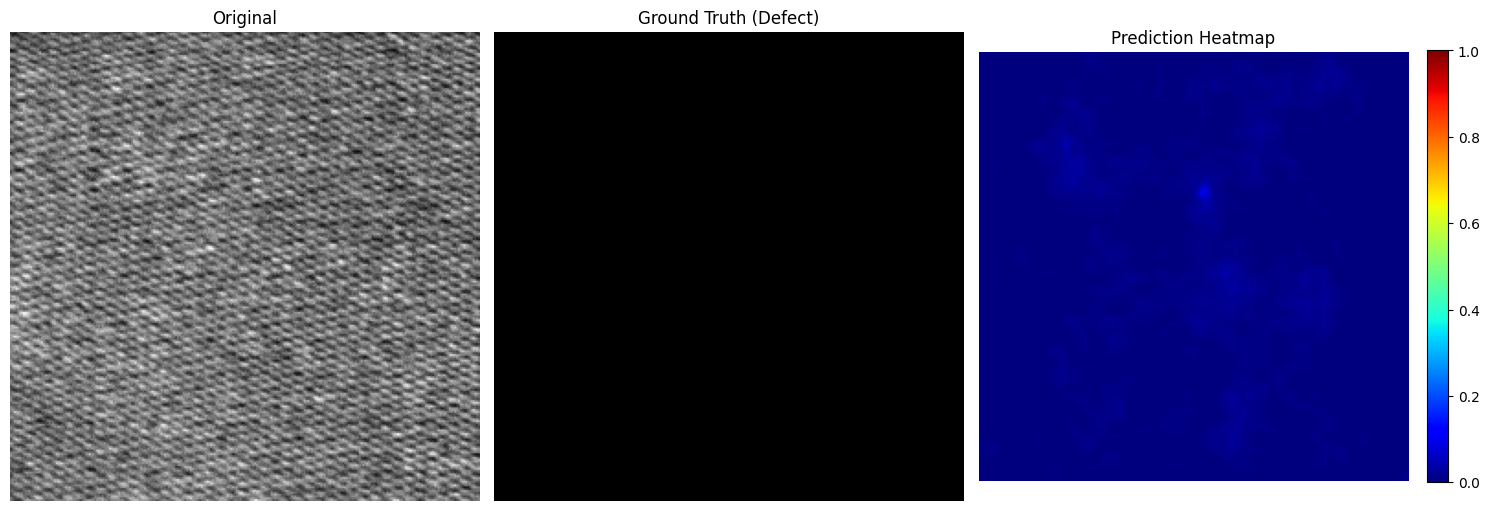

Sample 98: Pred Range [0.0001 - 0.9636]


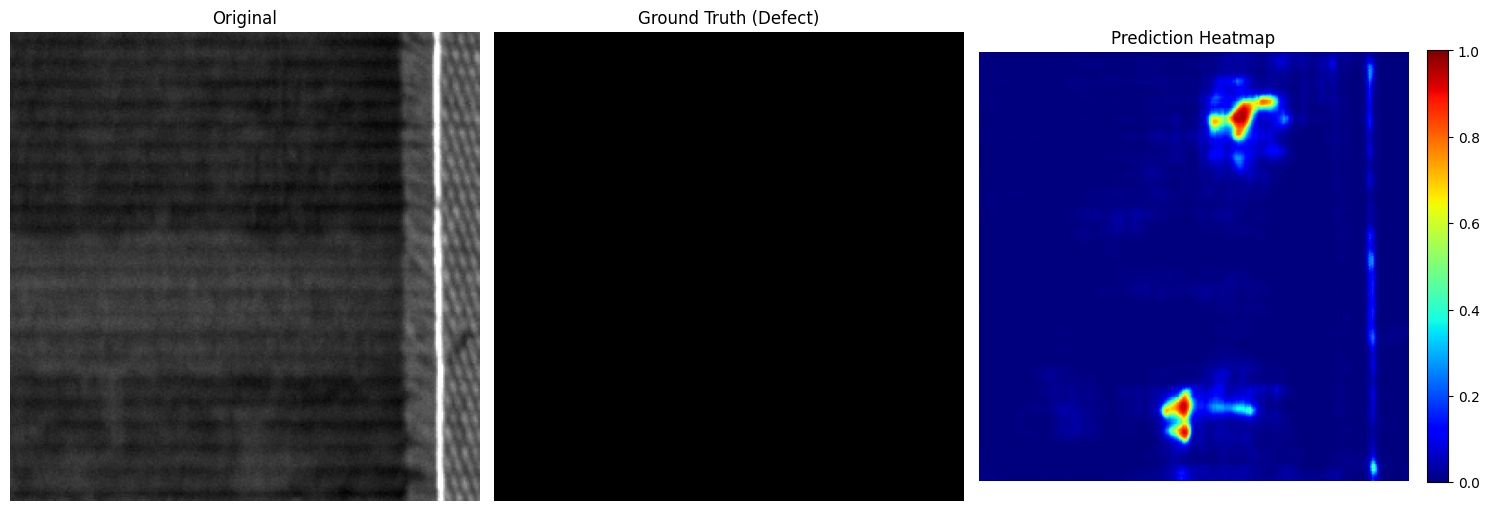

Sample 478: Pred Range [0.0000 - 0.0301]


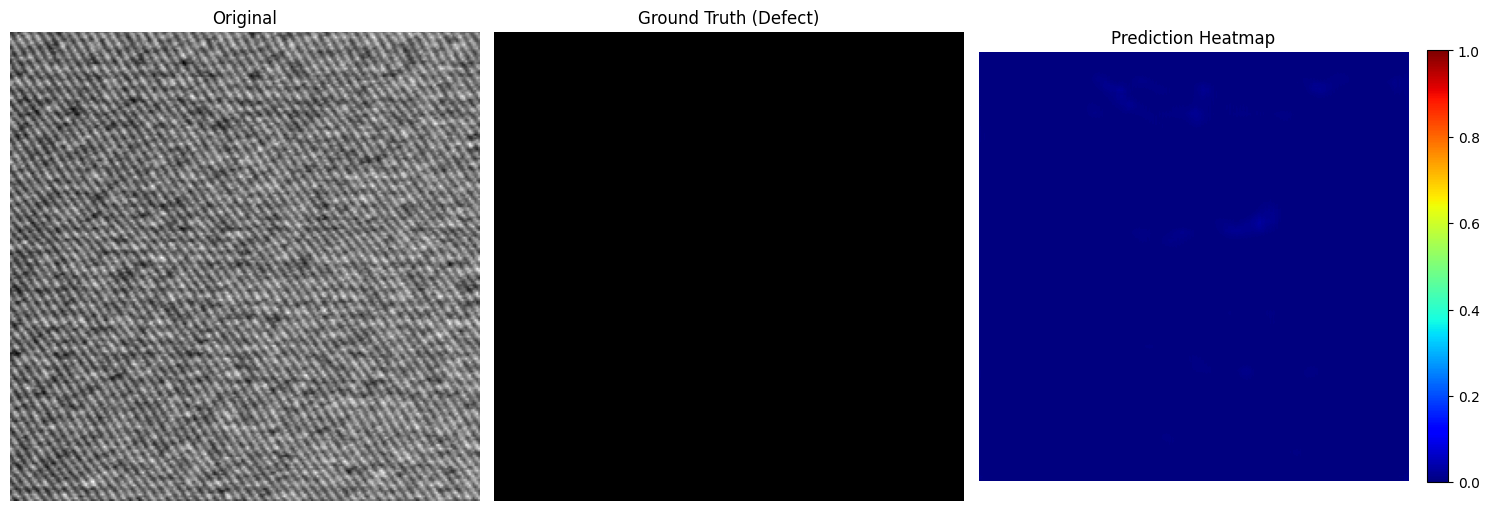

In [229]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Select a few samples to visualize
num_samples = 5
indices = np.random.choice(len(X_val), num_samples, replace=False)

print("--- VISUALIZING RAW PROBABILITY HEATMAPS ---")
print("Red/Yellow = High Probability of Defect")
print("Blue       = Low Probability (Background)\n")

for i in indices:
    # Get the data for this sample
    original_img = X_val[i].squeeze()
    ground_truth = y_val[i].squeeze()
    
    # Get the raw prediction (0.0 to 1.0)
    # We expand dims to make it (1, 256, 256, 1) for the model, then squeeze back
    raw_pred = model.predict(X_val[i:i+1], verbose=0).squeeze()
    
    # Check stats for this specific image
    p_min, p_max = raw_pred.min(), raw_pred.max()
    print(f"Sample {i}: Pred Range [{p_min:.4f} - {p_max:.4f}]")
    
    # Setup Plot
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 1. Original Image
    axes[0].imshow(original_img, cmap='gray')
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    # 2. Ground Truth
    axes[1].imshow(ground_truth, cmap='gray')
    axes[1].set_title("Ground Truth (Defect)")
    axes[1].axis('off')
    
    # 3. Prediction Heatmap (The Solution)
    # 'jet' cmap makes 0=Blue, 0.5=Green, 1.0=Red
    im = axes[2].imshow(raw_pred, cmap='jet', vmin=0, vmax=1) 
    axes[2].set_title("Prediction Heatmap")
    axes[2].axis('off')
    
    # Add colorbar to see values
    plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    plt.show()

* For defect detection, standard "Accuracy" is useless because 99.9% of the image is background. If the model says "no defect" for everything, it still gets 99.9% accuracy.
* Recall (Sensitivity) :

What it asks: "Out of all the real defects, how many did I find?"

Goal: You want this near 1.0 (100%).

Why: In manufacturing, missing a defect (False Negative) is worse than flagging a false alarm.

Your Notebook: Your val_recall was ~87%, but this is fake because the model was just guessing "everything is a defect" based on that 0.3 threshold.

* Precision :

What it asks: "Out of everything I claimed was a defect, how many were actually defects?"

Goal: Higher is better, but do not sacrifice Recall for it.

Why: Low precision means your system triggers too many false alarms, annoying the human operators.

* Dice Coefficient (F1-Score):

What it asks: "How good is the overlap between my prediction and the real defect?"

Goal: This is your single "truth" metric. If Recall is high but Dice is low, your model is just guessing.

Current Status: Your Dice is ~0.22, which confirms the model is performing poorly despite high Recall.